# Forecasting the Next Breakout Exports

**DATS 6103 · Fall 2026**  
**Mak Trnka · Galileo Perricone · Miguel Sanchez**

**Question** — Among products outside their country's top 10% of exports by dollar value,
which features predict entry the following year?

- Place the CSV beside this notebook, or update `DATA_PATH`.
- Run cells from top to bottom to regenerate results.
- Follow the sequence **data checks → coverage → group summaries → correlations → entry patterns**.
- Group tables summarize broad patterns; forecasting uses individual products.
- Missing records can affect rankings and shares.


## 1. Settings and data loading

| Use | Years |
|---|---|
| Descriptive tables | 2003–2016 |
| Exploratory relationships | Through 2012 |
| Final model testing | 2013–2016 |

- Read the CSV in chunks and retain `Export` records.
- Load commodity codes as text to preserve leading zeros.
- Fit and tune later models using chronological training and validation folds.

If packages are missing, run `%pip install pandas numpy matplotlib scipy` in a notebook cell.


In [128]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = Path("commodity_trade_statistics_data.csv")
START_YEAR = 2003
END_YEAR = 2016
EDA_END_YEAR = 2012
YEARS = list(range(START_YEAR, END_YEAR + 1))
CHUNK_SIZE = 500_000

pd.set_option("display.max_rows", 30)
pd.set_option("display.max_columns", 18)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

if not START_YEAR <= EDA_END_YEAR < END_YEAR:
    raise ValueError("Use START_YEAR <= EDA_END_YEAR < END_YEAR.")

SOURCE_COLUMNS = [
    "country_or_area", "year", "comm_code", "commodity", "flow",
    "trade_usd", "weight_kg", "quantity_name", "quantity", "category",
]
TEXT_COLUMNS = [
    "country_or_area", "comm_code", "commodity", "flow",
    "quantity_name", "category",
]


In [129]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"CSV not found at {DATA_PATH.resolve()}. Update DATA_PATH in the settings cell."
    )

source_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
missing_columns = sorted(set(SOURCE_COLUMNS) - set(source_columns))
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

source_rows = 0
invalid_year_rows = 0
flow_counts = pd.Series(dtype="int64")
export_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=SOURCE_COLUMNS,
    # Consistent types across chunks also make exact-duplicate checks reliable.
    dtype={column: "string" for column in SOURCE_COLUMNS if column != "year"},
    chunksize=CHUNK_SIZE,
):
    source_rows += len(chunk)
    flow = chunk["flow"].str.strip().str.lower().fillna("missing")
    flow_counts = flow_counts.add(flow.value_counts(), fill_value=0)

    year = pd.to_numeric(chunk["year"], errors="coerce")
    valid_year = year.notna() & year.mod(1).eq(0)
    invalid_year_rows += int((~valid_year).sum())
    keep = flow.eq("export") & valid_year & year.between(START_YEAR, END_YEAR)

    retained = chunk.loc[keep].copy()
    retained["year"] = year.loc[keep].astype(int)
    export_chunks.append(retained)

exports_period = pd.concat(export_chunks, ignore_index=True)
del export_chunks, chunk, retained

if exports_period.empty:
    raise ValueError("No Export records were found within the selected period.")

print(f"Source CSV: {source_rows:,} rows and {len(source_columns)} columns")
print(f"Source rows with missing or invalid years: {invalid_year_rows:,}")
print(f"Export rows in {START_YEAR}–{END_YEAR}: {len(exports_period):,}")
display(flow_counts.astype(int).sort_values(ascending=False).rename("source_rows").to_frame())
display(exports_period.head(10))


Source CSV: 8,225,871 rows and 10 columns
Source rows with missing or invalid years: 0
Export rows in 2003–2016: 1,737,741


,source_rows
flow,
import,4848524
export,2856309
re-export,367263
re-import,153775


,country_or_area,year,comm_code,commodity,flow,trade_usd,weight_kg,quantity_name,quantity,category
0,Afghanistan,2016,010410,"Sheep, live",Export,6088,2339,Number of items,51,01_live_animals
1,Afghanistan,2016,010420,"Goats, live",Export,3958,984,Number of items,53,01_live_animals
2,Albania,2016,010511,"Fowls, live domestic < 185 grams",Export,87581,5320,Number of items,115180,01_live_animals
3,Albania,2016,010600,"Animals, live, except farm animals",Export,584025,59521,Number of items,59521,01_live_animals
4,Albania,2015,010600,"Animals, live, except farm animals",Export,636184,80774,Number of items,80694,01_live_animals
5,Albania,2013,010600,"Animals, live, except farm animals",Export,846588,99329,No Quantity,<NA>,01_live_animals
6,Albania,2012,010290,"Bovine animals, live, except pure-bred breeding",Export,3390,2270,Number of items,22,01_live_animals
7,Albania,2012,010511,"Fowls, live domestic < 185 grams",Export,2480,360,Number of items,6000,01_live_animals
8,Albania,2012,010600,"Animals, live, except farm animals",Export,895347,119590,No Quantity,<NA>,01_live_animals
9,Albania,2011,010600,"Animals, live, except farm animals",Export,997424,137017,No Quantity,<NA>,01_live_animals


## 2. Check records before aggregation

| Check | Treatment |
|---|---|
| `TOTAL` / `all_commodities` | Keep separately for coverage checks |
| Product codes | Accept six digits or five with a missing leading zero; verify category |
| Other code formats | Exclude and list for review |
| Exact duplicates | Remove and count |
| Conflicting country–commodity–year rows | Stop for review |
| Missing, nonnumeric, infinite, or negative measurements | Set to null |
| Reported zeros | Retain as zero |


In [130]:
# Normalize text once, before checking identifiers and duplicates.
for column in TEXT_COLUMNS:
    exports_period[column] = exports_period[column].str.strip().replace("", pd.NA)

exports_period["flow"] = exports_period["flow"].str.lower()
exports_period["category"] = exports_period["category"].str.lower()
exports_period["comm_code"] = (
    exports_period["comm_code"].str.replace(r"\.0$", "", regex=True)
)

exact_duplicate_rows = int(exports_period.duplicated(SOURCE_COLUMNS).sum())
exports_period = exports_period.drop_duplicates(SOURCE_COLUMNS).copy()

measurement_audit_rows = []
for column in ["trade_usd", "weight_kg", "quantity"]:
    original_values = exports_period[column]
    values = pd.to_numeric(original_values, errors="coerce")
    invalid = values.lt(0) | (values.notna() & ~np.isfinite(values))

    measurement_audit_rows.append({
        "measurement": column,
        "missing_in_source": int(original_values.isna().sum()),
        "nonnumeric": int((original_values.notna() & values.isna()).sum()),
        "negative_or_infinite": int(invalid.sum()),
        "reported_zeros": int(values.eq(0).sum()),
    })
    exports_period[column] = values.mask(invalid)

chapter = exports_period["category"].str.extract(r"^(\d{2})_", expand=False)
valid_code = exports_period["comm_code"].str.fullmatch(r"\d{5,6}").fillna(False)
normalized_code = exports_period["comm_code"].str.zfill(6)
is_total = (
    exports_period["category"].eq("all_commodities")
    | exports_period["comm_code"].str.upper().eq("TOTAL")
).fillna(False)
valid_product = (
    ~is_total
    & valid_code
    & chapter.eq(normalized_code.str[:2]).fillna(False)
    & exports_period["country_or_area"].notna()
)

aggregate_exports = exports_period.loc[
    is_total & exports_period["country_or_area"].notna()
].copy()
excluded_products = exports_period.loc[~is_total & ~valid_product].copy()
product_exports = exports_period.loc[valid_product].copy()
product_exports["comm_code"] = normalized_code.loc[valid_product]

print(f"Exact duplicate rows removed: {exact_duplicate_rows:,}")
print(f"All-commodity total rows kept separately: {len(aggregate_exports):,}")
print(f"Other rows excluded by identifier/code checks: {len(excluded_products):,}")
display(pd.DataFrame(measurement_audit_rows))
display(excluded_products[["country_or_area", "comm_code", "category"]].head(10))

product_keys = ["country_or_area", "comm_code", "year"]
conflicting_products = product_exports.loc[
    product_exports.duplicated(product_keys, keep=False)
].sort_values(product_keys)

if not conflicting_products.empty:
    display(conflicting_products.head(30))
    raise ValueError(
        "Conflicting country–commodity–year rows remain. Inspect conflicting_products "
        "and resolve their meaning before summing or ranking them."
    )

if product_exports.empty:
    raise ValueError("No individual product records passed the code checks.")

print(f"Usable individual product records before country selection: {len(product_exports):,}")


Exact duplicate rows removed: 0
All-commodity total rows kept separately: 2,309
Other rows excluded by identifier/code checks: 35


,measurement,missing_in_source,nonnumeric,negative_or_infinite,reported_zeros
0,trade_usd,0,0,0,0
1,weight_kg,35211,0,0,7761
2,quantity,83788,0,0,8662


,country_or_area,comm_code,category
1733789,Brunei Darussalam,9999AA,99_commodities_not_specified_according_to_kind
1733815,Burundi,9999AA,99_commodities_not_specified_according_to_kind
1734107,Fiji,9999AA,99_commodities_not_specified_according_to_kind
1734108,Fiji,9999AA,99_commodities_not_specified_according_to_kind
1734151,Gabon,9999AA,99_commodities_not_specified_according_to_kind
1734195,Ghana,9999AA,99_commodities_not_specified_according_to_kind
1734246,Guyana,9999AA,99_commodities_not_specified_according_to_kind
1734247,Guyana,9999AA,99_commodities_not_specified_according_to_kind
1734283,Iceland,9999AA,99_commodities_not_specified_according_to_kind
1734398,Jordan,9999AA,99_commodities_not_specified_according_to_kind


Usable individual product records before country selection: 1,735,397


## 3. Country coverage, 2003–2016

- Select countries with an `Export` record in **every year**.
- Also count years with individual products; aggregate totals alone cannot supply rankings.
- Calculate country counts from the CSV. Matrix zeros mean no observed product rows.
- Selection through 2016 favors consistent reporters. Annual records can still omit products.


Selected countries: 100
Selected product export records: 1,365,917


,years_with_any_export,years_with_product_records,selected
country_or_area,,,
Albania,14,14,True
Algeria,14,14,True
Argentina,14,14,True
Armenia,14,14,True
Aruba,14,14,True
...,...,...,...
USA,14,14,True
United Arab Emirates,14,14,True
United Kingdom,14,14,True


Year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
Country,,,,,,,,,,,,,,
Albania,1204,1279,1232,1265,1259,1384,1492,1538,1588,1691,1673,404,665,925
Algeria,1007,768,936,1022,1063,941,883,783,673,767,805,852,885,875
Argentina,3967,4002,4060,4037,3861,3847,3797,3727,3696,3612,3550,3457,3391,3353
Armenia,1198,1201,1333,1411,1396,1354,1314,1210,1294,1364,1340,1278,1627,1620
Aruba,1,1,115,1,1,1,1132,1029,1046,1114,1100,1065,1076,1174
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
USA,472,470,469,470,442,443,442,443,443,451,474,471,471,474
United Arab Emirates,1,1,383,1,452,413,1,1,1,428,430,431,419,417
United Kingdom,464,468,468,475,446,445,440,446,443,443,443,449,449,453


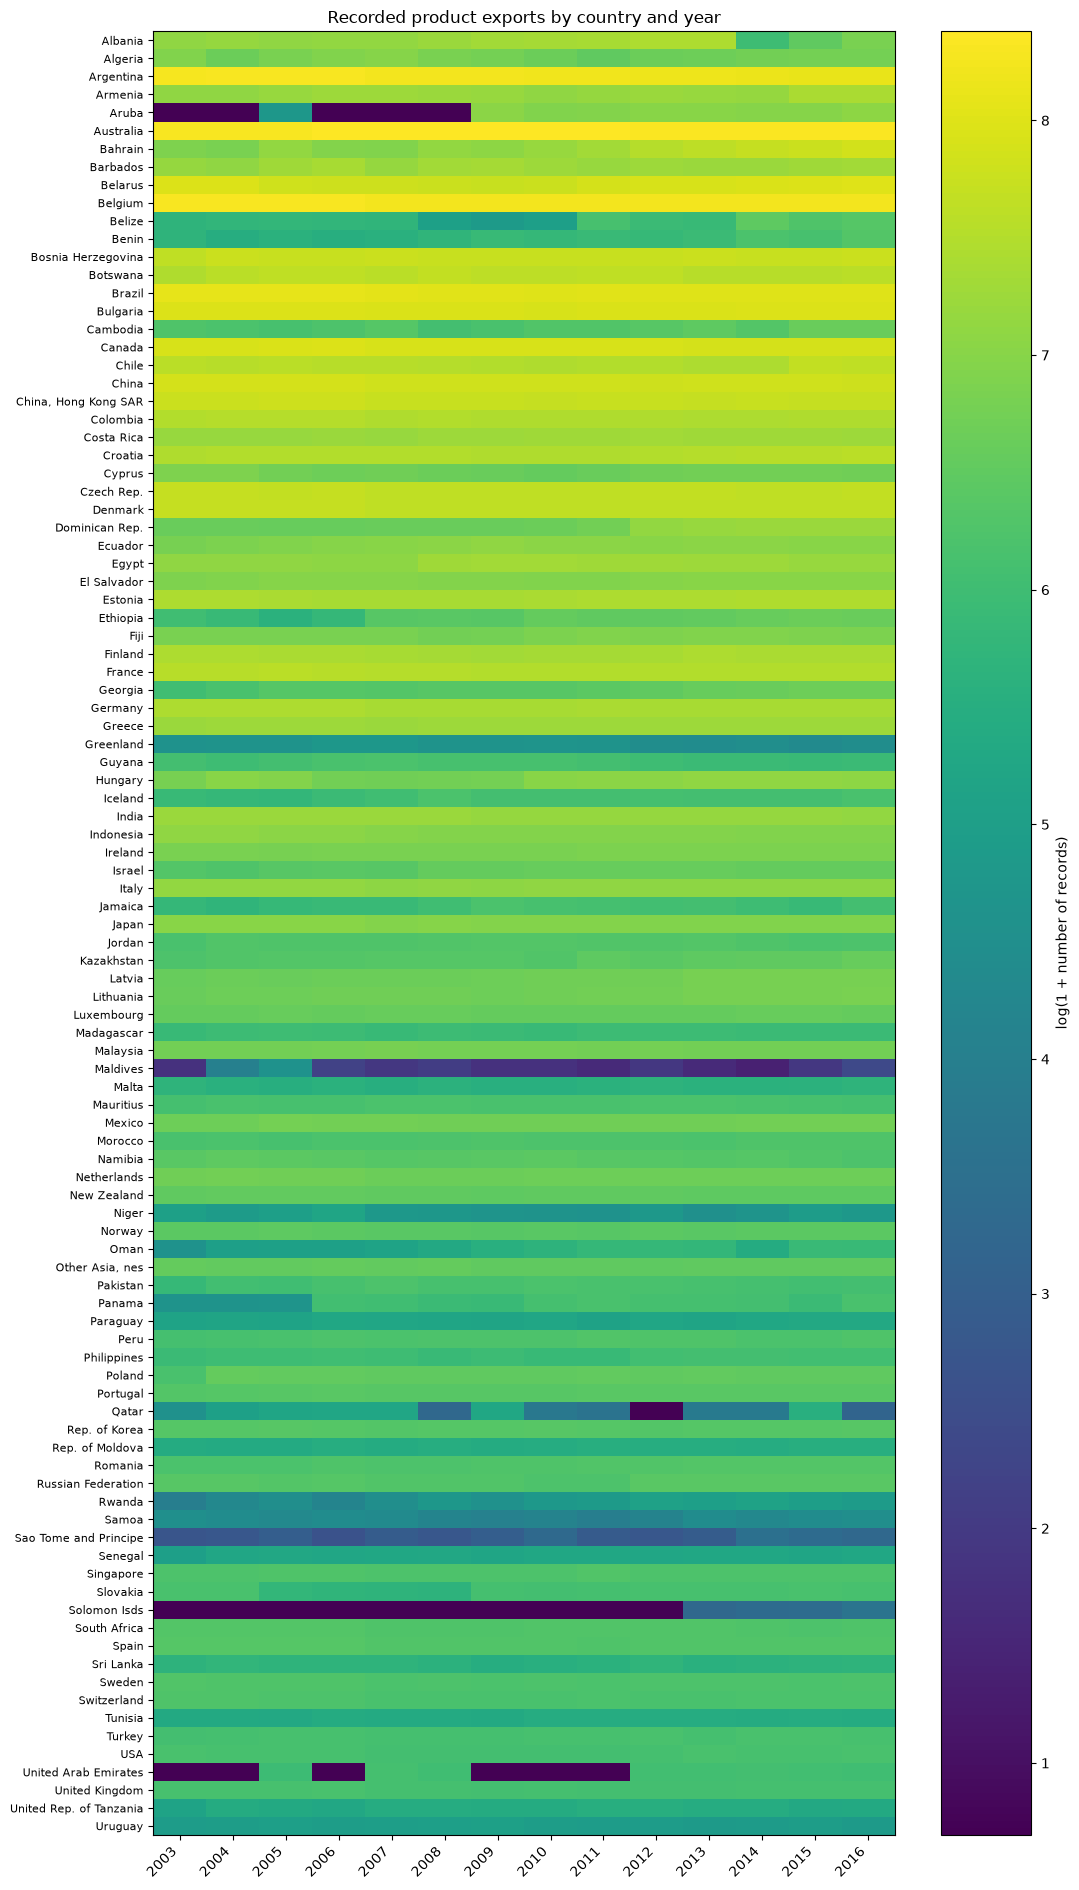

In [131]:
export_years = exports_period.groupby("country_or_area")["year"].nunique()
product_years = product_exports.groupby("country_or_area")["year"].nunique()

country_coverage = export_years.rename("years_with_any_export").to_frame()
country_coverage["years_with_product_records"] = (
    product_years.reindex(country_coverage.index, fill_value=0)
)
country_coverage["selected"] = country_coverage["years_with_any_export"].eq(len(YEARS))
selected_countries = country_coverage.index[country_coverage["selected"]].sort_values()

if len(selected_countries) == 0:
    raise ValueError("No country has an Export record in every selected year.")

exports = product_exports.loc[
    product_exports["country_or_area"].isin(selected_countries)
].copy()

country_year_counts = (
    exports.groupby(["country_or_area", "year"]).size()
    .unstack("year", fill_value=0)
    .reindex(index=selected_countries, columns=YEARS, fill_value=0)
    .rename_axis(index="Country", columns="Year")
)

print(f"Selected countries: {len(selected_countries):,}")
print(f"Selected product export records: {len(exports):,}")
display(country_coverage.loc[selected_countries])
display(country_year_counts)

fig, ax = plt.subplots(figsize=(11, max(5, len(selected_countries) * 0.19)))
image = ax.imshow(np.log1p(country_year_counts.to_numpy()), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(YEARS)), YEARS, rotation=45, ha="right")
ax.set_yticks(range(len(selected_countries)), selected_countries, fontsize=8)
ax.set_title("Recorded product exports by country and year")
fig.colorbar(image, ax=ax, label="log(1 + number of records)")
plt.tight_layout()
plt.show()


### Compare recorded products with reported totals

- Divide summed product USD by the source's all-commodity USD total.
- Review low ratios for limited coverage and ratios above 100% for inconsistencies.
- Leave missing or conflicting aggregate totals null; exclude them from product rankings.


In [132]:
country_year_index = pd.MultiIndex.from_product(
    [selected_countries, YEARS], names=["country_or_area", "year"]
)

product_coverage = exports.groupby(["country_or_area", "year"]).agg(
    product_records=("comm_code", "size"),
    records_with_value=("trade_usd", "count"),
    records_with_weight=("weight_kg", "count"),
)
product_coverage["recorded_product_usd"] = (
    exports.groupby(["country_or_area", "year"])["trade_usd"].sum(min_count=1)
)

aggregate_values = (
    aggregate_exports[["country_or_area", "year", "trade_usd"]]
    .dropna(subset=["trade_usd"]).drop_duplicates()
)
aggregate_conflicts = aggregate_values.duplicated(["country_or_area", "year"], keep=False)
print(f"Conflicting aggregate-total rows excluded from comparison: {aggregate_conflicts.sum():,}")
aggregate_values = aggregate_values.loc[~aggregate_conflicts].set_index(["country_or_area", "year"])

coverage_diagnostics = product_coverage.join(
    aggregate_values["trade_usd"].rename("reported_all_commodity_usd")
).reindex(country_year_index)

coverage_diagnostics["recorded_value_pct_of_reported_total"] = (
    coverage_diagnostics["recorded_product_usd"]
    .div(coverage_diagnostics["reported_all_commodity_usd"].where(
        coverage_diagnostics["reported_all_commodity_usd"].gt(0)
    )).mul(100)
)
coverage_diagnostics["weight_reporting_pct"] = (
    coverage_diagnostics["records_with_weight"]
    .div(coverage_diagnostics["product_records"]).mul(100)
)

display(coverage_diagnostics)
display(coverage_diagnostics[
    ["recorded_value_pct_of_reported_total", "weight_reporting_pct"]
].describe())


Conflicting aggregate-total rows excluded from comparison: 0


product_records  records_with_value  \
country_or_area year                                        
Albania         2003             1204                1204   
                2004             1279                1279   
                2005             1232                1232   
                2006             1265                1265   
                2007             1259                1259   
...                               ...                 ...   
Uruguay         2012              137                 137   
                2013              132                 132   
                2014              136                 136   
                2015              144                 144   
                2016              132                 132   

                      records_with_weight  recorded_product_usd  \
country_or_area year                                              
Albania         2003                 1171             447220543   
                2004                 1279             602653359   
                2005                 1232             658233160   
                2006                 1265             792629683   
                2007                 1187            1077690364   
...                                   ...                   ...   
Uruguay         2012                  136            1459134559   
                2013                  132            1210943517   
                2014                  136            1313966344   
                2015                  144             998399705   
                2016                  131             975039579   

                      reported_all_commodity_usd  \
country_or_area year                               
Albania         2003                   447220546   
                2004                   602653356   
                2005                   658233171   
                2006                   792629671   
                2007                  1077690359   
...                                          ...   
Uruguay         2012                  8709217341   
                2013                  9065753626   
                2014                  9165707594   
                2015                  7669514564   
                2016                  6963552025   

                      recorded_value_pct_of_reported_total  \
country_or_area year                                         
Albania         2003                               100.000   
                2004                               100.000   
                2005                               100.000   
                2006                               100.000   
                2007                               100.000   
...                                                    ...   
Uruguay         2012                                16.754   
                2013                                13.357   
                2014                                14.336   
                2015                                13.018   
                2016                                14.002   

                      weight_reporting_pct  
country_or_area year                        
Albania         2003                97.259  
                2004               100.000  
                2005               100.000  
                2006               100.000  
                2007                94.281  
...                                    ...  
Uruguay         2012                99.270  
                2013               100.000  
                2014               100.000  
                2015               100.000  
                2016                99.242  

[1400 rows x 7 columns]

,recorded_value_pct_of_reported_total,weight_reporting_pct
count,"1,400.000","1,400.000"
mean,46.769,96.396
std,32.680,12.958
min,0.299,0.000
25%,16.320,97.935
50%,39.596,99.641
75%,79.754,99.832
max,100.000,100.000


## 4. Categories and the 23 groups

| Level | Meaning |
|---|---|
| `comm_code` | Individual product |
| `category` | Broad commodity chapter |
| `commodity_group` | One of our 23 groups of related chapters |

Each product belongs to one group, including an unspecified-commodities group.
The category-by-country table counts each product code once across the selected years.


In [133]:
commodity_groups = {
    "animals_meat_seafood_dairy": [1, 2, 3, 4, 5, 16],
    "plants_and_crops": [6, 7, 8, 9, 10, 12, 13, 14],
    "processed_foods_oils_beverages_feed": [11, 15, 17, 18, 19, 20, 21, 22, 23],
    "tobacco": [24],
    "minerals_and_fuels": [25, 26, 27],
    "chemicals_and_related_products": list(range(28, 39)),
    "plastics_and_rubber": [39, 40],
    "hides_leather_and_fur": [41, 42, 43],
    "wood_paper_and_printed_goods": list(range(44, 50)),
    "textiles_and_clothing": list(range(50, 64)),
    "footwear_and_accessories": [64, 65, 66, 67],
    "stone_ceramics_and_glass": [68, 69, 70],
    "precious_stones_and_metals": [71],
    "base_metals_and_metal_goods": [72, 73, 74, 75, 76, 78, 79, 80, 81, 82, 83],
    "machinery_and_electronics": [84, 85],
    "transportation_equipment": [86, 87, 88, 89],
    "precision_instruments_and_timepieces": [90, 91],
    "musical_instruments": [92],
    "arms_and_ammunition": [93],
    "furniture_lighting_and_buildings": [94],
    "recreation_art_and_collectibles": [95, 97],
    "other_manufactured_goods": [96],
    "unspecified_commodities": [99],
}

group_by_chapter = {
    f"{chapter:02d}": group_name
    for group_name, chapters in commodity_groups.items()
    for chapter in chapters
}
assigned_chapters = [chapter for chapters in commodity_groups.values() for chapter in chapters]
assert len(assigned_chapters) == len(set(assigned_chapters)), "Groups overlap."

exports["commodity_group"] = exports["comm_code"].str[:2].map(group_by_chapter)
if exports["commodity_group"].isna().any():
    display(exports.loc[exports["commodity_group"].isna(), ["comm_code", "category"]].drop_duplicates())
    raise ValueError("Some product chapters are missing from commodity_groups.")

category_summary = exports.groupby("category").agg(
    export_records=("comm_code", "size"),
    distinct_commodities=("comm_code", "nunique"),
    exporting_countries=("country_or_area", "nunique"),
).sort_index()

category_country_counts = (
    exports.groupby(["category", "country_or_area"])["comm_code"].nunique()
    .unstack("country_or_area", fill_value=0)
    .reindex(columns=selected_countries, fill_value=0)
)

print(f"Distinct product categories: {len(category_summary)}")
display(category_summary)
display(category_country_counts)


Distinct product categories: 97


,export_records,distinct_commodities,exporting_countries
category,,,
01_live_animals,9990,15,100
02_meat_and_edible_meat_offal,17512,49,53
03_fish_crustaceans_molluscs_aquatic_invertebrates_ne,16800,87,33
04_dairy_products_eggs_honey_edible_animal_product_nes,18259,25,76
05_products_of_animal_origin_nes,10281,17,100
...,...,...,...
94_furniture_lighting_signs_prefabricated_buildings,17247,37,40
95_toys_games_sports_requisites,14977,43,46
96_miscellaneous_manufactured_articles,17086,50,36


country_or_area,Albania,Algeria,Argentina,Armenia,Aruba,Australia,Bahrain,Barbados,Belarus,...,Sweden,Switzerland,Tunisia,Turkey,USA,United Arab Emirates,United Kingdom,United Rep. of Tanzania,Uruguay
category,,,,,,,,,,,,,,,,,,,
01_live_animals,5,6,11,11,10,15,11,11,12,...,15,14,8,12,15,14,15,15,10
02_meat_and_edible_meat_offal,19,18,42,22,27,49,47,16,39,...,0,0,0,0,0,0,0,0,0
03_fish_crustaceans_molluscs_aquatic_invertebrates_ne,60,57,55,27,35,87,59,37,54,...,0,0,0,0,0,0,0,0,0
04_dairy_products_eggs_honey_edible_animal_product_nes,19,18,24,18,19,25,23,20,25,...,0,0,0,0,0,0,0,0,0
05_products_of_animal_origin_nes,7,2,12,6,4,17,8,9,14,...,17,17,11,15,17,16,17,16,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94_furniture_lighting_signs_prefabricated_buildings,36,31,37,36,34,37,37,37,37,...,0,0,0,0,0,0,0,0,0
95_toys_games_sports_requisites,17,9,43,30,28,43,39,42,43,...,0,0,0,0,0,0,0,0,0
96_miscellaneous_manufactured_articles,40,30,49,41,37,49,49,48,47,...,0,0,0,0,0,0,0,0,0


### Compare group size and value

- Count countries with at least one record in each group.
- Sum nominal export USD across the selected years.
- Interpret country counts as sample coverage and dollar totals as recorded trade value.


,export_records,distinct_commodities,exporting_countries,records_with_value,records_with_weight,total_export_usd,total_weight_kg,weight_reporting_pct
commodity_group,,,,,,,,
minerals_and_fuels,49969,163,99,49969,49021,10619286984559,43827540870488,98.103
unspecified_commodities,1240,1,100,1240,0,8039508265811,<NA>,0.000
chemicals_and_related_products,158714,742,100,158714,156519,6621420176618,3344731936635,98.617
transportation_equipment,53269,132,100,53269,50289,6590553506280,902845953848,94.406
processed_foods_oils_beverages_feed,141511,233,100,141511,140959,4400379829100,15383746619260,99.610
base_metals_and_metal_goods,143972,548,100,143972,143081,3783011285277,1449657319686,99.381
precious_stones_and_metals,18071,50,53,18071,16538,2992873393395,5887401429,91.517
plants_and_crops,106688,236,100,106688,106254,2657377801522,6065552975969,99.593
animals_meat_seafood_dairy,90468,218,100,90468,89155,2527269433302,935017171105,98.549


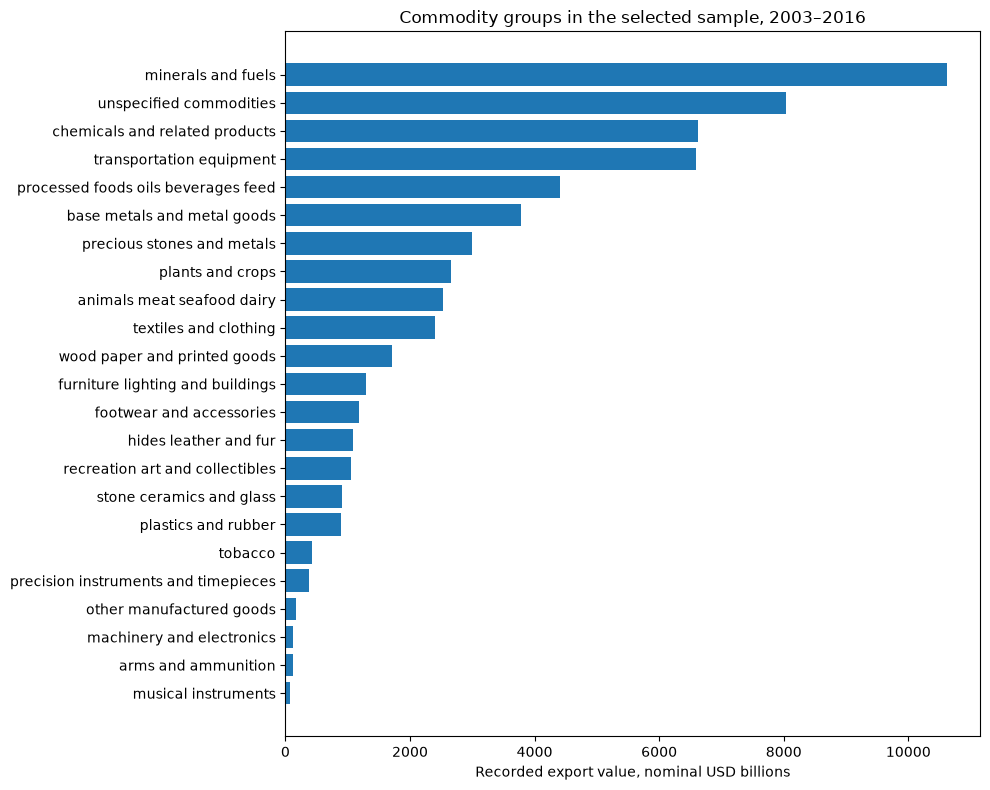

In [134]:
grouped_exports = exports.groupby("commodity_group", sort=False)
export_datasets = {
    name: grouped_exports.get_group(name).copy()
    if name in grouped_exports.groups else exports.iloc[:0].copy()
    for name in commodity_groups
}

group_summary = grouped_exports.agg(
    export_records=("comm_code", "size"),
    distinct_commodities=("comm_code", "nunique"),
    exporting_countries=("country_or_area", "nunique"),
    records_with_value=("trade_usd", "count"),
    records_with_weight=("weight_kg", "count"),
)
group_summary[["total_export_usd", "total_weight_kg"]] = (
    grouped_exports[["trade_usd", "weight_kg"]].sum(min_count=1)
)
group_summary = group_summary.reindex(list(commodity_groups))
count_columns = [
    "export_records", "distinct_commodities", "exporting_countries",
    "records_with_value", "records_with_weight",
]
group_summary[count_columns] = group_summary[count_columns].fillna(0).astype(int)
group_summary["weight_reporting_pct"] = (
    group_summary["records_with_weight"]
    .div(group_summary["export_records"].replace(0, np.nan)).mul(100)
)
group_summary = group_summary.sort_values("total_export_usd", ascending=False)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(group_summary)

plot_values = group_summary["total_export_usd"].dropna().sort_values() / 1e9
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_values.index.str.replace("_", " "), plot_values.values)
ax.set_xlabel("Recorded export value, nominal USD billions")
ax.set_title(f"Commodity groups in the selected sample, {START_YEAR}–{END_YEAR}")
plt.tight_layout()
plt.show()


## 5. Country–year totals by group

- Give all 23 groups the same country–year grid.
- Leave missing observations null and retain reported zeros.
- Sum available USD and kilograms separately.
- Sum quantities by unit; treat `No Quantity` and similar labels as missing units.
- Use reporting counts to identify partial totals, especially for weight.


In [135]:
NO_UNIT_LABELS = ["", "no quantity", "unknown", "not specified", "n/a"]

def summarize_commodity_group(group_name):
    data = export_datasets[group_name]
    keys = ["country_or_area", "year"]
    grouped = data.groupby(keys)

    summary = grouped[["trade_usd", "weight_kg"]].sum(min_count=1).rename(columns={
        "trade_usd": "total_export_usd",
        "weight_kg": "total_weight_kg",
    })
    summary["distinct_commodities"] = grouped["comm_code"].nunique()
    summary["export_records"] = grouped.size()
    summary["records_with_value"] = grouped["trade_usd"].count()
    summary["records_with_weight"] = grouped["weight_kg"].count()

    quantities = data[keys + ["quantity", "quantity_name"]].copy()
    quantities["unit"] = quantities["quantity_name"].str.strip().str.lower().replace(NO_UNIT_LABELS, pd.NA)
    reported = quantities.dropna(subset=["unit", "quantity"])
    if not reported.empty:
        quantity_totals = (
            reported.groupby(keys + ["unit"])["quantity"].sum(min_count=1)
            .unstack("unit").add_prefix("quantity | ")
        )
        summary = summary.join(quantity_totals)

    summary = summary.reindex(country_year_index)
    for column in ["distinct_commodities", "export_records", "records_with_value", "records_with_weight"]:
        summary[column] = summary[column].astype("Int64")

    summary = summary.reset_index().rename(columns={"country_or_area": "country"})
    summary.insert(2, "commodity_group", group_name)
    main_columns = [
        "country", "year", "commodity_group", "distinct_commodities",
        "total_export_usd", "total_weight_kg", "export_records",
        "records_with_value", "records_with_weight",
    ]
    quantity_columns = sorted(column for column in summary if column.startswith("quantity | "))
    return summary[main_columns + quantity_columns]


group_totals = {
    name: summarize_commodity_group(name)
    for name in commodity_groups
}
country_year_totals = pd.concat(group_totals.values(), ignore_index=True)

print(f"Created {len(group_totals)} group tables, each with {len(country_year_index):,} rows.")
display(country_year_totals.head(15))


Created 23 group tables, each with 1,400 rows.


,country,year,commodity_group,distinct_commodities,total_export_usd,total_weight_kg,export_records,records_with_value,records_with_weight,...,quantity | weight in kilograms,quantity | electrical energy in thousands of kilowatt-hours,quantity | area in square metres,quantity | length in metres,quantity | volume in cubic meters,quantity | number of pairs,quantity | thousands of items,quantity | weight in carats,quantity | number of packages
0,Albania,2003,animals_meat_seafood_dairy,39,15354247,2861201,39,39,39,...,2859867,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,Albania,2004,animals_meat_seafood_dairy,44,18576677,3669498,44,44,44,...,3561919,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,Albania,2005,animals_meat_seafood_dairy,40,20130287,3824163,40,40,40,...,3680816,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,Albania,2006,animals_meat_seafood_dairy,53,26984767,5782188,53,53,53,...,5557820,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
4,Albania,2007,animals_meat_seafood_dairy,41,29338541,4976965,41,41,40,...,4976030,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
5,Albania,2008,animals_meat_seafood_dairy,48,41970741,8001630,48,48,48,...,7919415,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
6,Albania,2009,animals_meat_seafood_dairy,48,42791927,6409327,48,48,48,...,6355151,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
7,Albania,2010,animals_meat_seafood_dairy,53,46854766,9000977,53,53,53,...,8906334,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
8,Albania,2011,animals_meat_seafood_dairy,49,51427155,8702519,49,49,49,...,8565502,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
9,Albania,2012,animals_meat_seafood_dairy,59,52564074,10732175,59,59,59,...,10609955,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


### Inspect one group

Change `GROUP_TO_VIEW` to any key in `commodity_groups`.

| Dataset | Contents |
|---|---|
| `export_datasets[group_name]` | Individual export records |
| `group_totals[group_name]` | Country–year summaries with null gaps |


In [136]:
GROUP_TO_VIEW = "machinery_and_electronics"

group_table = group_totals[GROUP_TO_VIEW]
observed_countries = (
    export_datasets[GROUP_TO_VIEW]["country_or_area"].dropna().drop_duplicates().sort_values()
)
print(f"{GROUP_TO_VIEW}: {len(observed_countries)} countries with recorded exports")
display(observed_countries.reset_index(drop=True).to_frame("country"))

# Includes null rows for selected countries without observations in this group.
with pd.option_context("display.max_columns", None):
    display(group_table)


machinery_and_electronics: 7 countries with recorded exports


,country
0,Albania
1,Algeria
2,Argentina
3,Armenia
4,Aruba
5,Australia
6,Bahrain


,country,year,commodity_group,distinct_commodities,total_export_usd,total_weight_kg,export_records,records_with_value,records_with_weight,quantity | number of items,quantity | weight in kilograms
0,Albania,2003,machinery_and_electronics,199,14684287,1975451,199,199,195,429788,1052719
1,Albania,2004,machinery_and_electronics,213,21233774,10718319,213,213,213,956249,8693007
2,Albania,2005,machinery_and_electronics,208,24965447,7452437,208,208,208,1910546,5835020
3,Albania,2006,machinery_and_electronics,227,28611698,8077867,227,227,227,1951630,6398337
4,Albania,2007,machinery_and_electronics,228,41312974,45435806,228,228,213,109782,44335481
...,...,...,...,...,...,...,...,...,...,...,...
1395,Uruguay,2012,machinery_and_electronics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1396,Uruguay,2013,machinery_and_electronics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1397,Uruguay,2014,machinery_and_electronics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1398,Uruguay,2015,machinery_and_electronics,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


## 6. Relationships within groups

- Use **Spearman correlation** on complete country–year pairs through 2012.
- Compare USD with kilograms, USD with product count, and kilograms with product count.
- Review sample counts, weight coverage, country size, and time trends when interpreting results.

| Heatmap color | Meaning |
|---|---|
| Red | Positive correlation |
| Blue | Negative correlation |
| Gray | Undefined correlation |

The scale runs from **−1 to +1**. Small samples can produce unstable estimates.


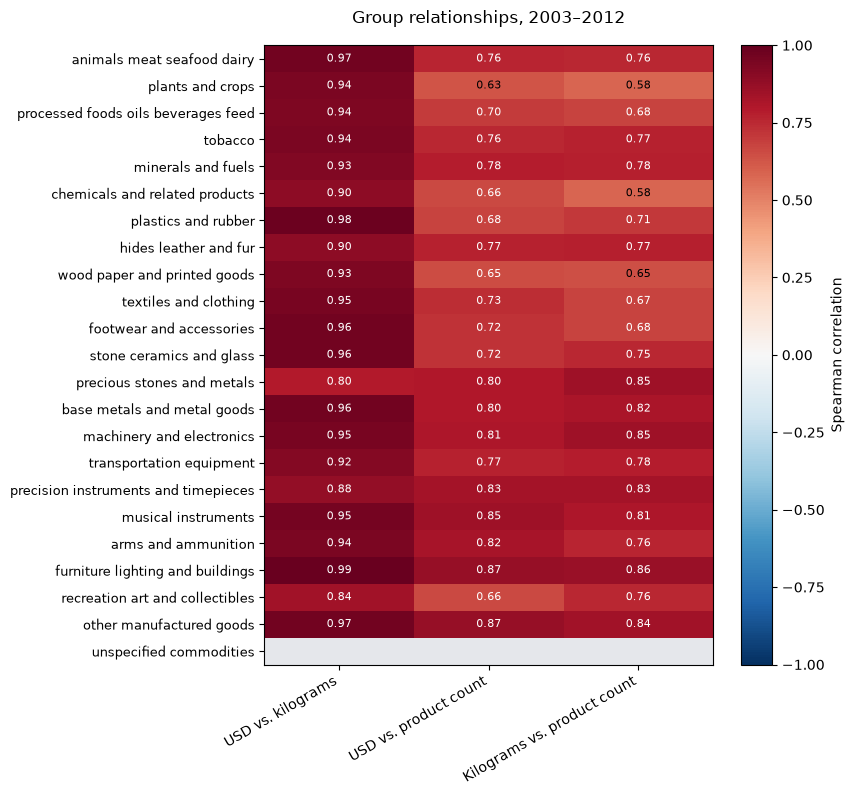

Complete country–year pairs used in each cell


,USD vs. kilograms,USD vs. product count,Kilograms vs. product count
animals_meat_seafood_dairy,967,967,967
plants_and_crops,968,968,968
processed_foods_oils_beverages_feed,978,978,978
tobacco,937,937,937
minerals_and_fuels,934,935,934
chemicals_and_related_products,958,958,958
plastics_and_rubber,282,282,282
hides_leather_and_fur,956,956,956
wood_paper_and_printed_goods,965,966,965
textiles_and_clothing,961,963,961


In [143]:
def correlation_tables(data, group_column, comparisons, group_order):
    correlations = pd.DataFrame(np.nan, index=group_order, columns=list(comparisons))
    counts = pd.DataFrame(0, index=group_order, columns=list(comparisons), dtype=int)

    for group_name, group in data.groupby(group_column):
        for label, (x_column, y_column) in comparisons.items():
            pairs = group[[x_column, y_column]].replace([np.inf, -np.inf], np.nan).dropna()
            counts.loc[group_name, label] = len(pairs)
            if len(pairs) >= 3 and pairs.nunique().ge(2).all():
                correlations.loc[group_name, label] = pairs[x_column].corr(
                    pairs[y_column], method="spearman"
                )
    return correlations, counts


def plot_correlation_heatmap(matrix, title):
    if matrix.empty or not matrix.notna().any().any():
        print(f"{title}: no correlations can be calculated.")
        return

    values = matrix.to_numpy(dtype=float, na_value=np.nan)
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("#e5e7eb")
    fig, ax = plt.subplots(figsize=(max(8, 1.5 * len(matrix.columns) + 4), max(5, 0.35 * len(matrix))))
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(matrix)), matrix.index.str.replace("_", " "), fontsize=9)
    for row, column in np.argwhere(np.isfinite(values)):
        value = values[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center",
                fontsize=8, color="white" if abs(value) > 0.65 else "black")
    ax.set_title(title, pad=16)
    fig.colorbar(image, ax=ax, label="Spearman correlation")
    plt.tight_layout()
    plt.show()


group_eda = country_year_totals.loc[country_year_totals["year"].le(EDA_END_YEAR)].copy()
group_comparisons = {
    "USD vs. kilograms": ("total_export_usd", "total_weight_kg"),
    "USD vs. product count": ("total_export_usd", "distinct_commodities"),
    "Kilograms vs. product count": ("total_weight_kg", "distinct_commodities"),
}
group_correlations, group_correlation_counts = correlation_tables(
    group_eda, "commodity_group", group_comparisons, list(commodity_groups)
)
plot_correlation_heatmap(group_correlations, f"Group relationships, {START_YEAR}–{EDA_END_YEAR}")
print("Complete country–year pairs used in each cell")
display(group_correlation_counts)


### USD and quantity by unit

- Use records with both USD and quantity present.
- Sum both measures from the same records, separately for each unit.
- For example, compare liters with USD from the records measured in liters.


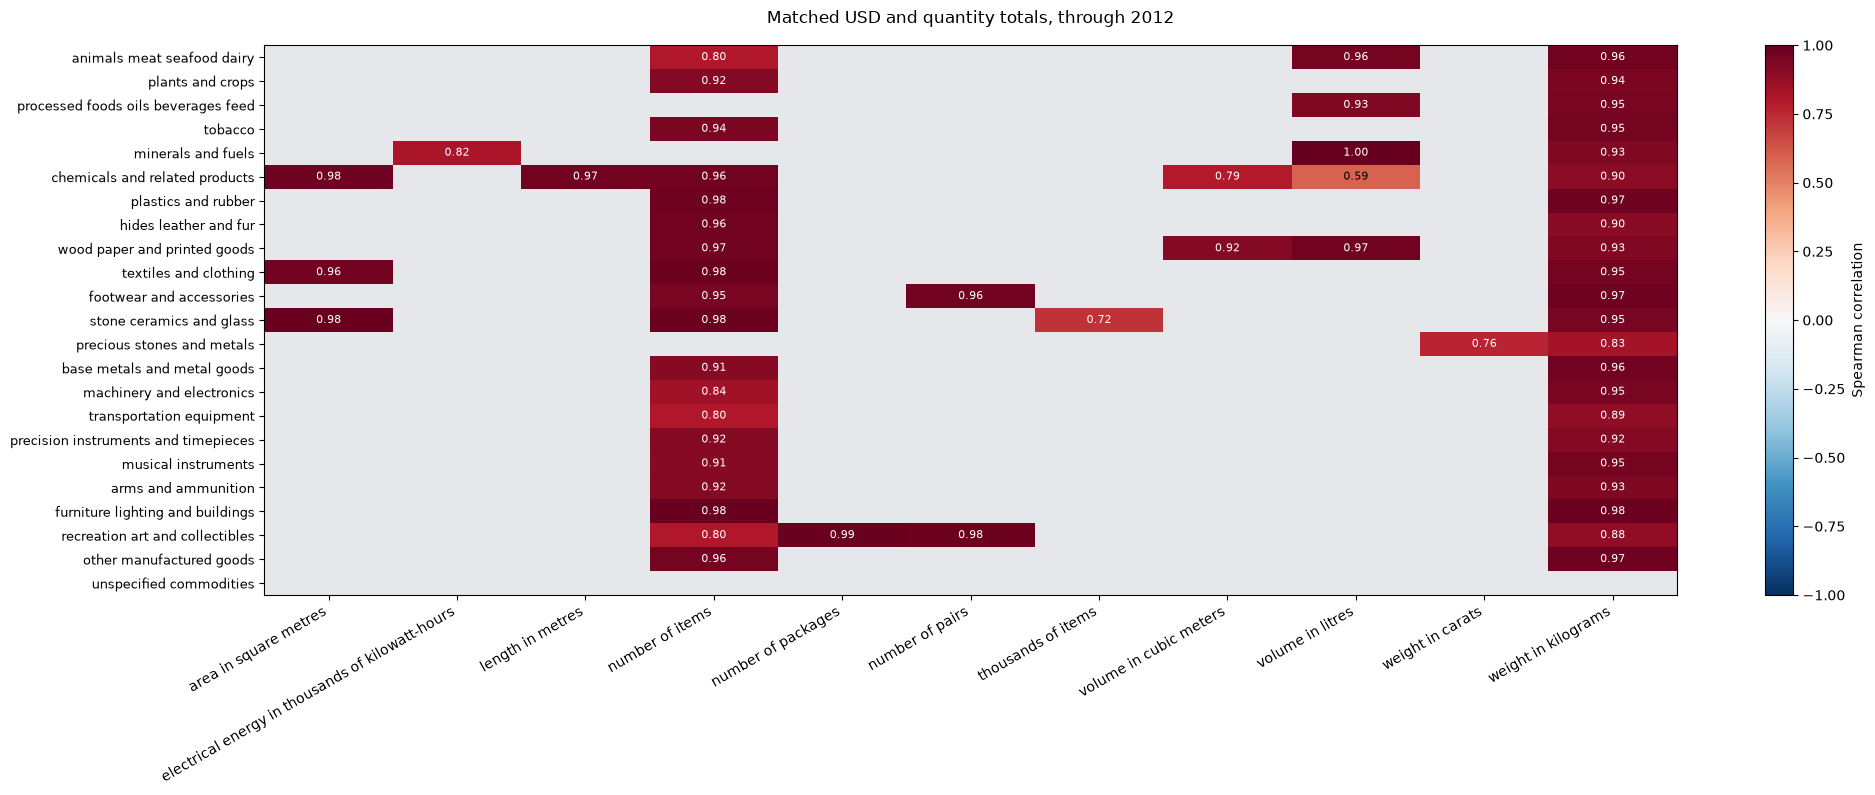

Complete country–year pairs used for each quantity unit


,area in square metres,electrical energy in thousands of kilowatt-hours,length in metres,number of items,number of packages,number of pairs,thousands of items,volume in cubic meters,volume in litres,weight in carats,weight in kilograms
animals_meat_seafood_dairy,0,0,0,870,0,0,0,0,17,0,960
plants_and_crops,0,0,0,746,0,0,0,0,0,0,968
processed_foods_oils_beverages_feed,0,0,0,0,0,0,0,0,795,0,978
tobacco,0,0,0,18,0,0,0,0,0,0,936
minerals_and_fuels,0,273,0,0,0,0,0,0,7,0,934
chemicals_and_related_products,519,0,480,230,0,0,0,71,15,0,958
plastics_and_rubber,0,0,0,263,0,0,0,0,0,0,282
hides_leather_and_fur,2,0,0,672,0,2,0,0,0,0,953
wood_paper_and_printed_goods,1,0,0,298,0,0,0,305,12,0,965
textiles_and_clothing,811,0,0,248,0,0,0,0,0,0,951


In [144]:
quantity_records = exports.loc[
    exports["year"].le(EDA_END_YEAR),
    ["commodity_group", "country_or_area", "year", "trade_usd", "quantity", "quantity_name"],
].copy()
quantity_records["unit"] = (
    quantity_records["quantity_name"].str.strip().str.lower().replace(NO_UNIT_LABELS, pd.NA)
)
quantity_records = quantity_records.dropna(subset=["unit", "trade_usd", "quantity"])
quantity_pairs = (
    quantity_records.groupby(["commodity_group", "country_or_area", "year", "unit"])
    [["trade_usd", "quantity"]].sum(min_count=1).reset_index()
)

unit_correlations = pd.DataFrame(index=list(commodity_groups), dtype=float)
unit_counts = pd.DataFrame(index=list(commodity_groups), dtype=int)
for unit, unit_data in quantity_pairs.groupby("unit"):
    coefficients, counts = correlation_tables(
        unit_data, "commodity_group", {unit: ("trade_usd", "quantity")}, list(commodity_groups)
    )
    unit_correlations[unit] = coefficients[unit]
    unit_counts[unit] = counts[unit]

plot_correlation_heatmap(unit_correlations, f"Matched USD and quantity totals, through {EDA_END_YEAR}")
print("Complete country–year pairs used for each quantity unit")
display(unit_counts)


## 7. Individual-product rankings and labels

- Rank all accepted products within each country-year through 2012.
- Use `ceil(10% × product count)` for the cutoff; break value ties by commodity code.
- Forecast products currently outside the cutoff.
- Leave rankings and value shares null when a country-year has missing product values.
- Leave absent next-year products unlabeled. Shares use recorded USD or reported kilograms.

Labels describe the observed product universe. Review coverage gaps and classification
changes before final modeling.


In [139]:
records = exports.loc[exports["year"].le(EDA_END_YEAR)].copy()
records = records.sort_values(["country_or_area", "year", "comm_code"]).reset_index(drop=True)
national = records.groupby(["country_or_area", "year"])

records["product_count"] = national["comm_code"].transform("size")
records["value_reporting_complete"] = national["trade_usd"].transform("count").eq(records["product_count"])
records["country_export_usd"] = national["trade_usd"].transform("sum", min_count=1)
records["country_weight_kg"] = national["weight_kg"].transform("sum", min_count=1)
records["weight_reporting_pct"] = (
    national["weight_kg"].transform("count").div(records["product_count"]).mul(100)
)

records["export_rank"] = national["trade_usd"].rank(ascending=False, method="first").where(
    records["value_reporting_complete"]
)
records["top10_count"] = np.ceil(records["product_count"] * 0.10).astype(int)
records["in_top10"] = records["export_rank"].le(records["top10_count"]).astype("boolean")
records.loc[~records["value_reporting_complete"], "in_top10"] = pd.NA

records["value_share_pct"] = (
    records["trade_usd"].div(records["country_export_usd"].where(
        records["country_export_usd"].gt(0) & records["value_reporting_complete"]
    )).mul(100)
)
records["weight_share_pct"] = (
    records["weight_kg"].div(records["country_weight_kg"].where(records["country_weight_kg"].gt(0))).mul(100)
)

display(records[[
    "country_or_area", "year", "comm_code", "commodity", "export_rank",
    "product_count", "in_top10", "value_share_pct", "weight_share_pct",
]].head(15))


,country_or_area,year,comm_code,commodity,export_rank,product_count,in_top10,value_share_pct,weight_share_pct
0,Albania,2003,010111,"Horses, live pure-bred breeding",861.000,1204,False,0.001,0.000
1,Albania,2003,010600,"Animals, live, except farm animals",425.000,1204,False,0.007,0.000
2,Albania,2003,020110,"Bovine carcasses and half carcasses, fresh or ...",240.000,1204,False,0.023,0.004
3,Albania,2003,020130,"Bovine cuts boneless, fresh or chilled",824.000,1204,False,0.001,0.001
4,Albania,2003,020742,"Turkey cuts & offal, except livers, frozen",400.000,1204,False,0.008,0.002
5,Albania,2003,020820,"Frog legs, fresh, chilled or frozen",57.000,1204,True,0.225,0.034
6,Albania,2003,030211,"Trout, fresh or chilled, whole",608.000,1204,False,0.003,0.001
7,Albania,2003,030219,"Salmonidae, not trout or salmon,fresh or chill...",609.000,1204,False,0.003,0.002
8,Albania,2003,030222,"Plaice, fresh or chilled, whole",822.000,1204,False,0.001,0.000
9,Albania,2003,030229,"Flatfish, fresh/chilled not halibut/plaice/sol...",679.000,1204,False,0.002,0.001


### Align predictors with outcomes

| For a 2012 outcome | Input years |
|---|---|
| Three annual growth rates | 2008–09, 2009–10, 2010–11 |
| Two value and weight shares | 2010 and 2011 |

- Join exact calendar years to preserve gaps.
- With data starting in 2003, the first possible four-year-history outcome is 2007.
- A zero starting value gives null growth; a fall from positive value to zero gives −100%.


In [140]:
join_keys = ["country_or_area", "comm_code", "feature_year"]

history = records.rename(columns={
    "year": "feature_year",
    "trade_usd": "value_latest",
    "in_top10": "already_top10",
    "value_share_pct": "value_share_one_year_before_pct",
    "weight_share_pct": "weight_share_one_year_before_pct",
}).copy()

for lag in [1, 2, 3]:
    columns = ["country_or_area", "comm_code", "year", "trade_usd"]
    if lag == 1:
        columns += ["value_share_pct", "weight_share_pct"]
    earlier = records[columns].copy()
    earlier["feature_year"] = earlier.pop("year") + lag
    earlier = earlier.rename(columns={
        "trade_usd": f"value_lag{lag}",
        "value_share_pct": "value_share_two_years_before_pct",
        "weight_share_pct": "weight_share_two_years_before_pct",
    })
    history = history.merge(earlier, on=join_keys, how="left", validate="one_to_one")

growth_intervals = {
    "growth_oldest_pct": ("value_lag2", "value_lag3"),
    "growth_middle_pct": ("value_lag1", "value_lag2"),
    "growth_latest_pct": ("value_latest", "value_lag1"),
}
for name, (ending, starting) in growth_intervals.items():
    history[name] = history[ending].div(history[starting].where(history[starting].gt(0))).sub(1).mul(100)

future = records[["country_or_area", "comm_code", "year", "in_top10", "product_count"]].copy()
future["feature_year"] = future.pop("year") - 1
future = future.rename(columns={"in_top10": "enters_next_year", "product_count": "next_year_product_count"})
history = history.merge(future, on=join_keys, how="left", validate="one_to_one")
history["outcome_year"] = history["feature_year"] + 1
history["rank_distance"] = history["export_rank"] - history["top10_count"]
history["relative_distance_pct"] = history["rank_distance"].div(history["product_count"]).mul(100)

forecast_eligible = history.loc[
    history["already_top10"].eq(False).fillna(False)
    & history["outcome_year"].between(START_YEAR + 4, EDA_END_YEAR)
].copy()
forecast_eda = forecast_eligible.dropna(subset=["enters_next_year"]).copy()
forecast_eda["enters_next_year"] = forecast_eda["enters_next_year"].astype(int)

predictor_columns = [
    "growth_oldest_pct", "growth_middle_pct", "growth_latest_pct",
    "value_share_one_year_before_pct", "value_share_two_years_before_pct",
    "weight_share_one_year_before_pct", "weight_share_two_years_before_pct",
]
forecast_eda[predictor_columns] = forecast_eda[predictor_columns].replace([np.inf, -np.inf], np.nan)

print(f"Eligible historical observations: {len(forecast_eligible):,}")
print(f"Unassigned next-year outcomes: {forecast_eligible['enters_next_year'].isna().sum():,}")
print(f"Labeled observations for exploration: {len(forecast_eda):,}")

label_summary = forecast_eda.groupby("outcome_year")["enters_next_year"].agg(
    observations="size", entrants="sum", entry_rate="mean"
)
label_summary["entry_rate_pct"] = label_summary.pop("entry_rate") * 100
display(label_summary)

predictor_missingness = pd.DataFrame({
    "missing_observations": forecast_eda[predictor_columns].isna().sum(),
    "missing_pct": forecast_eda[predictor_columns].isna().mean() * 100,
})
display(predictor_missingness)

growth_columns = list(growth_intervals)
growth_coverage = forecast_eda.assign(
    three_valid_growth_rates=forecast_eda[growth_columns].notna().all(axis=1)
).groupby("commodity_group").agg(
    labeled_observations=("enters_next_year", "size"),
    observations_with_all_growth_rates=("three_valid_growth_rates", "sum"),
)
display(growth_coverage.reindex(list(commodity_groups)))


Eligible historical observations: 520,441
Unassigned next-year outcomes: 60,967
Labeled observations for exploration: 459,474


,observations,entrants,entry_rate_pct
outcome_year,,,
2007,74517,1115,1.496
2008,75767,1262,1.666
2009,76015,1281,1.685
2010,76853,1255,1.633
2011,77933,1185,1.521
2012,78389,1200,1.531


,missing_observations,missing_pct
growth_oldest_pct,63393,13.797
growth_middle_pct,54851,11.938
growth_latest_pct,32576,7.090
value_share_one_year_before_pct,0,0.000
value_share_two_years_before_pct,32576,7.090
weight_share_one_year_before_pct,8045,1.751
weight_share_two_years_before_pct,40086,8.724


,labeled_observations,observations_with_all_growth_rates
commodity_group,,
animals_meat_seafood_dairy,29221,24261
plants_and_crops,36635,30998
processed_foods_oils_beverages_feed,46203,39223
tobacco,2261,1816
minerals_and_fuels,15058,11804
chemicals_and_related_products,53656,45962
plastics_and_rubber,11037,9351
hides_leather_and_fur,14821,12611
wood_paper_and_printed_goods,23617,20172


### Examine entry rates

- Compare entry rates by category and prior distance from the cutoff.
- Check sample sizes before interpreting differences.
- Use distance patterns to assess the rationale for the closest-to-cutoff baseline.


,observations,entrants,entry_rate_pct
category,,,
99_commodities_not_specified_according_to_kind,87,31,35.632
89_ships_boats_and_other_floating_structures,3548,230,6.483
88_aircraft_spacecraft_and_parts_thereof,2833,168,5.930
87_vehicles_other_than_railway_tramway,4592,201,4.377
24_tobacco_and_manufactured_tobacco_substitutes,2261,93,4.113
...,...,...,...
37_photographic_or_cinematographic_goods,4836,10,0.207
67_bird_skin_feathers_artificial_flowers_human_hair,2491,5,0.201
92_musical_instruments_parts_and_accessories,5306,10,0.188


,observations,entrants,entry_rate_pct
rank_distance,,,
1,554,231,41.697
2–5,2224,795,35.746
6–10,2759,719,26.060
11–25,8157,1418,17.384
26–50,13421,1163,8.666
Over 50,432359,2972,0.687


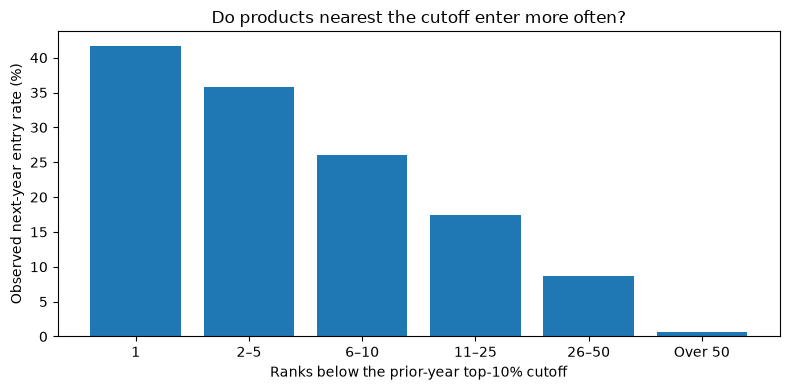

In [141]:
entry_by_category = forecast_eda.groupby("category")["enters_next_year"].agg(
    observations="size", entrants="sum", entry_rate="mean"
)
entry_by_category["entry_rate_pct"] = entry_by_category.pop("entry_rate") * 100
display(entry_by_category.sort_values("entry_rate_pct", ascending=False))

distance_band = pd.cut(
    forecast_eda["rank_distance"],
    bins=[0, 1, 5, 10, 25, 50, np.inf],
    labels=["1", "2–5", "6–10", "11–25", "26–50", "Over 50"],
)
entry_by_distance = forecast_eda.groupby(distance_band, observed=False)["enters_next_year"].agg(
    observations="size", entrants="sum", entry_rate="mean"
)
entry_by_distance["entry_rate_pct"] = entry_by_distance.pop("entry_rate") * 100
display(entry_by_distance)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(entry_by_distance.index.astype(str), entry_by_distance["entry_rate_pct"])
ax.set_xlabel("Ranks below the prior-year top-10% cutoff")
ax.set_ylabel("Observed next-year entry rate (%)")
ax.set_title("Do products nearest the cutoff enter more often?")
plt.tight_layout()
plt.show()


## 8. Six predictor relationships

Use eligible products with outcomes through 2012. Spearman correlations exclude missing
values pair by pair, so sample counts may differ. Products repeat across years.

| Comparison | Interpretation |
|---|---|
| Prior growth vs. entry | Positive suggests faster-growing products enter more often |
| Prior value share vs. entry | Positive associates larger shares with entry |
| Prior distance vs. entry | Negative associates proximity to the cutoff with entry |
| Prior weight shares vs. entry | Positive associates greater weight shares with entry |
| Value vs. weight shares | Same-year correlations show overlap between predictors |
| Consecutive growth rates | Positive suggests persistence; negative suggests reversal in relative growth |

Negative growth correlation alone does not establish a change from growth to decline.
The model's categorical predictor remains `category`; the 23 groups organize these plots.


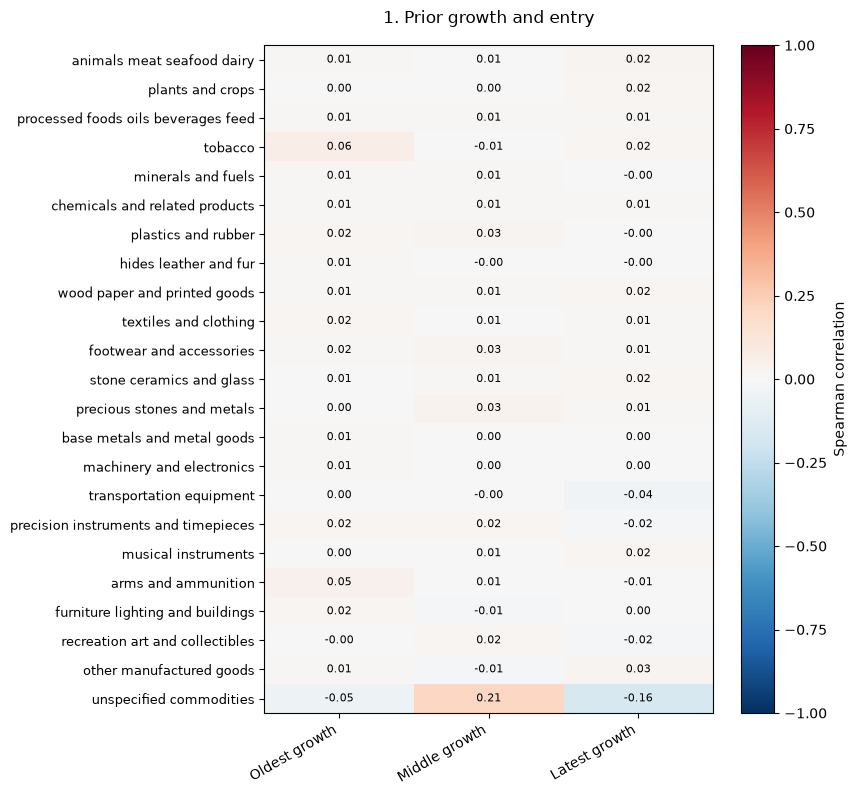

1. Prior growth and entry — complete product-year pairs


,Oldest growth,Middle growth,Latest growth
animals_meat_seafood_dairy,24842,25495,27005
plants_and_crops,31721,32436,34153
processed_foods_oils_beverages_feed,40029,41022,43188
tobacco,1878,1927,2069
minerals_and_fuels,12217,12552,13521
chemicals_and_related_products,46967,47824,50153
plastics_and_rubber,9559,9743,10274
hides_leather_and_fur,12873,13151,13857
wood_paper_and_printed_goods,20627,21011,22073
textiles_and_clothing,67286,68548,72032


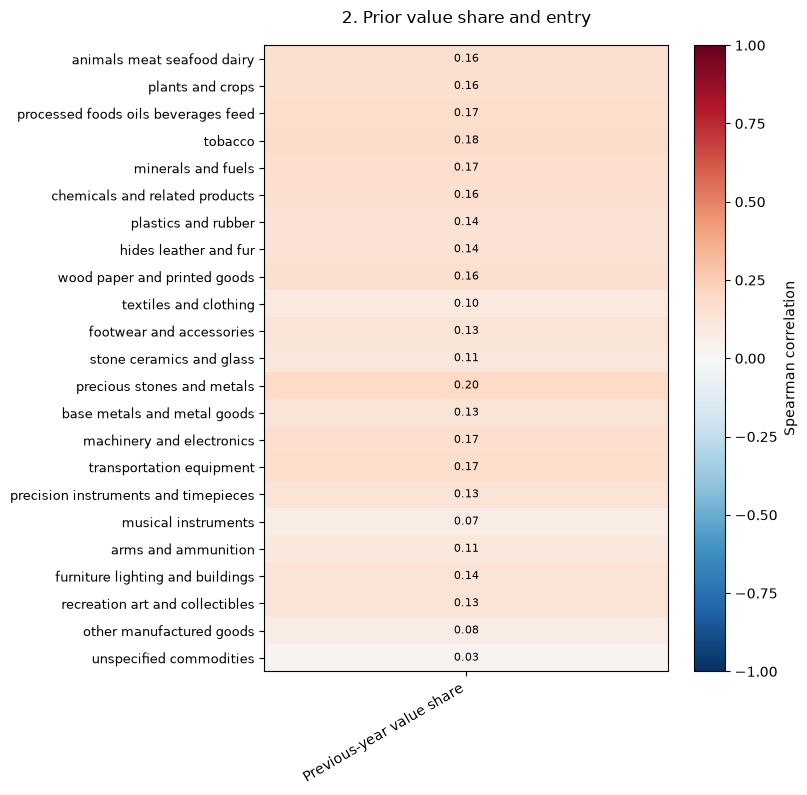

2. Prior value share and entry — complete product-year pairs


,Previous-year value share
animals_meat_seafood_dairy,29221
plants_and_crops,36635
processed_foods_oils_beverages_feed,46203
tobacco,2261
minerals_and_fuels,15058
chemicals_and_related_products,53656
plastics_and_rubber,11037
hides_leather_and_fur,14821
wood_paper_and_printed_goods,23617
textiles_and_clothing,77038


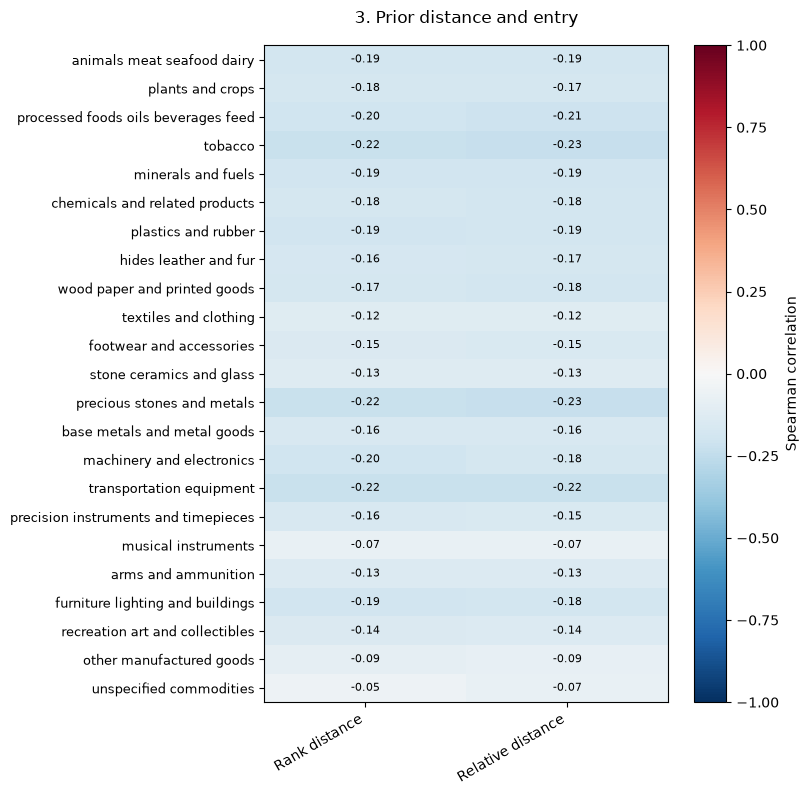

3. Prior distance and entry — complete product-year pairs


,Rank distance,Relative distance
animals_meat_seafood_dairy,29221,29221
plants_and_crops,36635,36635
processed_foods_oils_beverages_feed,46203,46203
tobacco,2261,2261
minerals_and_fuels,15058,15058
chemicals_and_related_products,53656,53656
plastics_and_rubber,11037,11037
hides_leather_and_fur,14821,14821
wood_paper_and_printed_goods,23617,23617
textiles_and_clothing,77038,77038


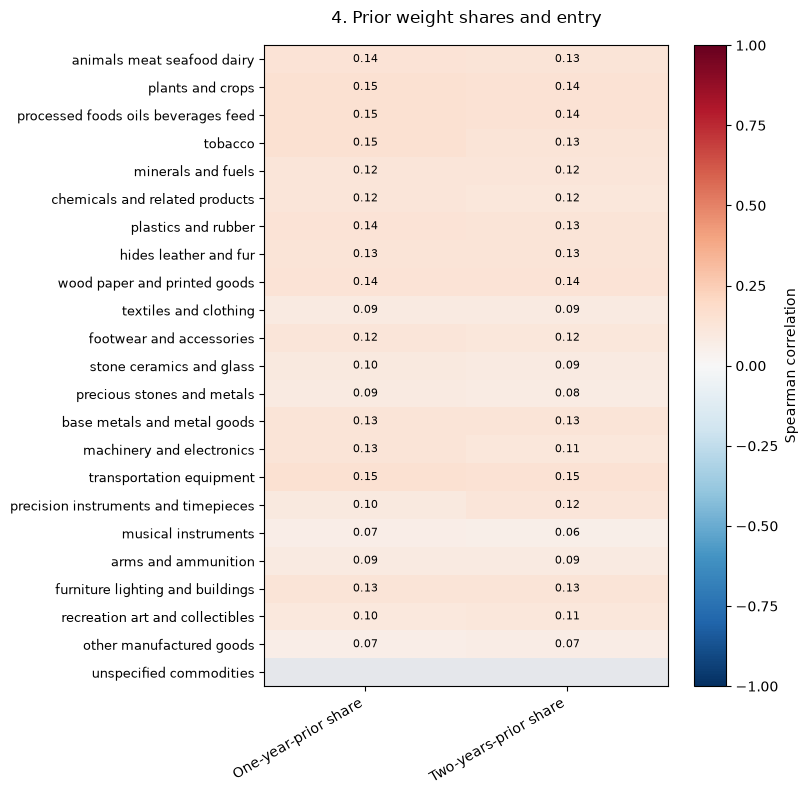

4. Prior weight shares and entry — complete product-year pairs


,One-year-prior share,Two-years-prior share
animals_meat_seafood_dairy,28719,26582
plants_and_crops,36502,34039
processed_foods_oils_beverages_feed,46077,43021
tobacco,2207,2018
minerals_and_fuels,14920,13399
chemicals_and_related_products,52977,49557
plastics_and_rubber,11005,10244
hides_leather_and_fur,14504,13572
wood_paper_and_printed_goods,23299,21724
textiles_and_clothing,75924,71038


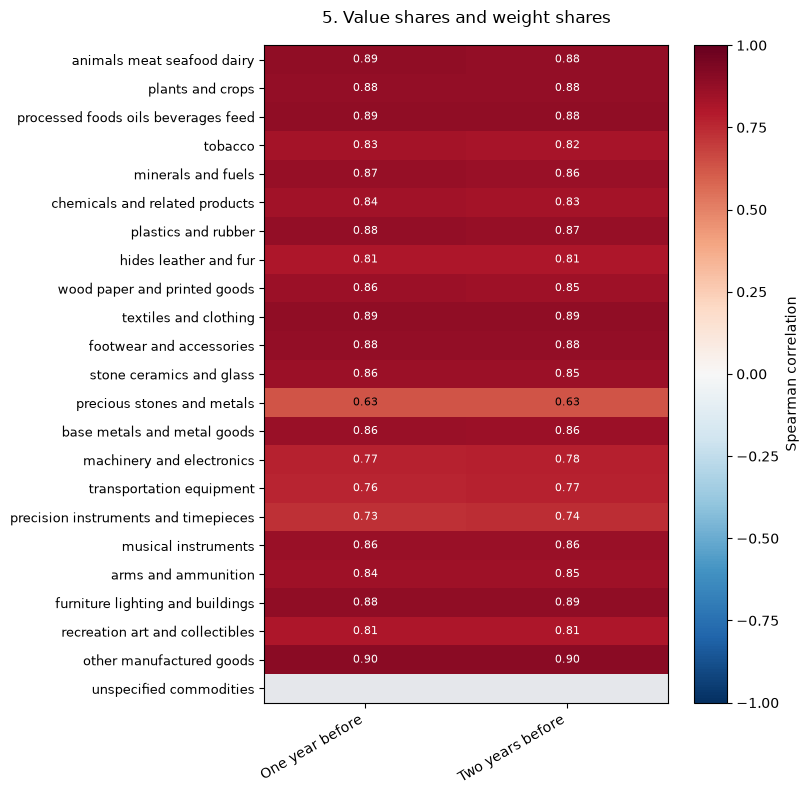

5. Value shares and weight shares — complete product-year pairs


,One year before,Two years before
animals_meat_seafood_dairy,28719,26582
plants_and_crops,36502,34039
processed_foods_oils_beverages_feed,46077,43021
tobacco,2207,2018
minerals_and_fuels,14920,13399
chemicals_and_related_products,52977,49557
plastics_and_rubber,11005,10244
hides_leather_and_fur,14504,13572
wood_paper_and_printed_goods,23299,21724
textiles_and_clothing,75924,71038


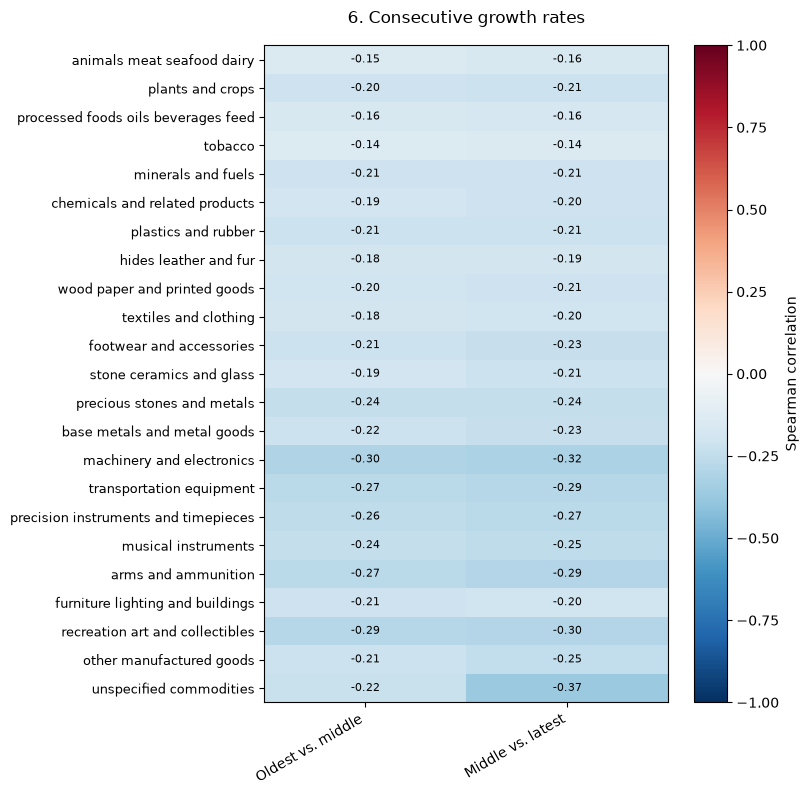

6. Consecutive growth rates — complete product-year pairs


,Oldest vs. middle,Middle vs. latest
animals_meat_seafood_dairy,24261,25495
plants_and_crops,30998,32436
processed_foods_oils_beverages_feed,39223,41022
tobacco,1816,1927
minerals_and_fuels,11804,12552
chemicals_and_related_products,45962,47824
plastics_and_rubber,9351,9743
hides_leather_and_fur,12611,13151
wood_paper_and_printed_goods,20172,21011
textiles_and_clothing,65747,68548


In [142]:
predictor_comparisons = {
    "1. Prior growth and entry": {
        "Oldest growth": ("growth_oldest_pct", "enters_next_year"),
        "Middle growth": ("growth_middle_pct", "enters_next_year"),
        "Latest growth": ("growth_latest_pct", "enters_next_year"),
    },
    "2. Prior value share and entry": {
        "Previous-year value share": ("value_share_one_year_before_pct", "enters_next_year"),
    },
    "3. Prior distance and entry": {
        "Rank distance": ("rank_distance", "enters_next_year"),
        "Relative distance": ("relative_distance_pct", "enters_next_year"),
    },
    "4. Prior weight shares and entry": {
        "One-year-prior share": ("weight_share_one_year_before_pct", "enters_next_year"),
        "Two-years-prior share": ("weight_share_two_years_before_pct", "enters_next_year"),
    },
    "5. Value shares and weight shares": {
        "One year before": ("value_share_one_year_before_pct", "weight_share_one_year_before_pct"),
        "Two years before": ("value_share_two_years_before_pct", "weight_share_two_years_before_pct"),
    },
    "6. Consecutive growth rates": {
        "Oldest vs. middle": ("growth_oldest_pct", "growth_middle_pct"),
        "Middle vs. latest": ("growth_middle_pct", "growth_latest_pct"),
    },
}

predictor_correlations = {}
predictor_correlation_counts = {}

for title, comparisons in predictor_comparisons.items():
    coefficients, counts = correlation_tables(
        forecast_eda, "commodity_group", comparisons, list(commodity_groups)
    )
    predictor_correlations[title] = coefficients
    predictor_correlation_counts[title] = counts
    plot_correlation_heatmap(coefficients, title)
    print(f"{title} — complete product-year pairs")
    display(counts)


## 9. Findings and modeling decisions

After running the CSV, record:

- **Coverage** — eligible countries, sparse groups, and recorded value versus reported totals.
- **Quality** — missing values, duplicate conflicts, and changes in product coverage.
- **Patterns** — group values, entry rates, and correlations supported by adequate samples.
- **Model checks** — logistic regression and random forest versus majority-class and cutoff baselines.

Use chronological validation, matched observations for feature comparisons, and matched
shortlist sizes. Evaluate entry F1, precision, recall, and confusion matrices. Reserve
2013–2016 outcomes for final testing. Review coverage before treating labels as final.

### Main outputs

| DataFrame | Contents |
|---|---|
| `exports` | Selected 2003–2016 product records |
| `country_coverage`, `coverage_diagnostics` | Reporting checks |
| `category_summary`, `category_country_counts` | Category counts |
| `group_summary` | Totals and coverage for 23 groups |
| `country_year_totals` | All group summaries with null gaps |
| `forecast_eligible`, `forecast_eda` | Eligible observations and the labeled subset |
| `predictor_correlations`, `predictor_correlation_counts` | Coefficients and sample sizes |

**Verification** — Code passed tests using synthetic records. The raw CSV was not attached;
run locally to regenerate full-data results.
